# Data Quality and Exploratory Analysis: Customer Churn

**Objective:** build a reproducible, analysis-ready customer churn dataset and a defensible record of every data-quality decision, then inspect the first patterns.

**Dataset:** `data/customer_churn_sample.csv`, synthetic customer records (15 rows, 11 columns).

**How to reproduce:** put the raw CSV in `data/`, then run all cells top to bottom. Outputs are written to `data/customer_churn_clean.csv`, `data/data_dictionary.csv`, and `charts/`.

**Important caveat:** with only 15 customers, every pattern below is descriptive, not statistical evidence. Treat the findings as hypotheses to test on a larger sample.

In [1]:
import pandas as pd, numpy as np
import matplotlib.pyplot as plt

pd.set_option("display.width", 140)
pd.set_option("display.max_columns", 30)

RAW_PATH = "data/customer_churn_sample.csv"
raw = pd.read_csv(RAW_PATH)
df = raw.copy()          # raw is never modified; all cleaning happens on df
raw.head()

  CustomerID  Gender  Age  TenureMonths SubscriptionType  MonthlyCharges  TotalCharges    ContractType  SupportTickets  PaymentMethod Churn
0  CUST-1001  Female   34            12            Basic           49.99        599.88  Month-to-Month               3    Credit Card   Yes
1  CUST-1002    Male   45            24              Pro           79.99       1919.76        One Year               1  Bank Transfer    No
2  CUST-1003  Female   29             6            Basic           49.99        299.94  Month-to-Month               5            UPI   Yes
3  CUST-1004    Male   52            36       Enterprise          149.99       5399.64        Two Year               0    Credit Card    No
4  CUST-1005  Female   41             8              Pro           79.99        639.92  Month-to-Month               4     Debit Card   Yes

## 1. Profile the data

In [2]:
print("Shape (rows, columns):", raw.shape)
print()
raw.info()

Shape (rows, columns): (15, 11)

<class 'pandas.DataFrame'>
RangeIndex: 15 entries, 0 to 14
Data columns (total 11 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   CustomerID        15 non-null     str    
 1   Gender            15 non-null     str    
 2   Age               15 non-null     int64  
 3   TenureMonths      15 non-null     int64  
 4   SubscriptionType  15 non-null     str    
 5   MonthlyCharges    15 non-null     float64
 6   TotalCharges      15 non-null     float64
 7   ContractType      15 non-null     str    
 8   SupportTickets    15 non-null     int64  
 9   PaymentMethod     15 non-null     str    
 10  Churn             15 non-null     str    
dtypes: float64(2), int64(3), str(6)
memory usage: 1.4 KB


### 1.1 Missing values and duplicates

In [3]:
missing = raw.isna().sum().to_frame("missing_count")
missing["missing_pct"] = (missing["missing_count"] / len(raw) * 100).round(1)
print(missing)
print()
print("Fully duplicated rows        :", raw.duplicated().sum())
print("Duplicated CustomerID values :", raw["CustomerID"].duplicated().sum())
print("Blank / whitespace-only cells:", int(raw.select_dtypes("object").apply(lambda c: c.astype(str).str.strip().eq("")).sum().sum()))

                  missing_count  missing_pct
CustomerID                    0          0.0
Gender                        0          0.0
Age                           0          0.0
TenureMonths                  0          0.0
SubscriptionType              0          0.0
MonthlyCharges                0          0.0
TotalCharges                  0          0.0
ContractType                  0          0.0
SupportTickets                0          0.0
PaymentMethod                 0          0.0
Churn                         0          0.0

Fully duplicated rows        : 0
Duplicated CustomerID values : 0
Blank / whitespace-only cells: 0


### 1.2 Categorical consistency (spelling, case, stray whitespace)

In [4]:
cat_cols = ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]
for c in cat_cols:
    s = raw[c].astype(str)
    messy = (s != s.str.strip()).sum()
    print(f"{c:17s} levels={raw[c].nunique()}  values_with_stray_whitespace={messy}")
    print("   ", raw[c].value_counts().to_dict())

Gender            levels=2  values_with_stray_whitespace=0
    {'Female': 8, 'Male': 7}
SubscriptionType  levels=3  values_with_stray_whitespace=0
    {'Basic': 7, 'Pro': 4, 'Enterprise': 4}
ContractType      levels=3  values_with_stray_whitespace=0
    {'Month-to-Month': 7, 'One Year': 4, 'Two Year': 4}
PaymentMethod     levels=4  values_with_stray_whitespace=0
    {'Credit Card': 6, 'UPI': 4, 'Bank Transfer': 3, 'Debit Card': 2}
Churn             levels=2  values_with_stray_whitespace=0
    {'No': 8, 'Yes': 7}


### 1.3 Numeric ranges and outliers
Two checks: the IQR rule (outside Q1 - 1.5·IQR to Q3 + 1.5·IQR) and absolute z-scores above 3. Domain-rule checks (no negatives, plausible age) follow.

In [5]:
num_cols = ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]
rows = []
for c in num_cols:
    s = raw[c]
    q1, q3 = s.quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
    z = ((s - s.mean()) / s.std()).abs()
    rows.append({"column": c, "min": s.min(), "max": s.max(), "IQR_low": round(lo,2), "IQR_high": round(hi,2),
                 "IQR_outliers": int(((s < lo) | (s > hi)).sum()), "z>3_outliers": int((z > 3).sum()),
                 "negatives": int((s < 0).sum())})
outlier_report = pd.DataFrame(rows).set_index("column")
outlier_report

                  min      max  IQR_low  IQR_high  IQR_outliers  z>3_outliers  negatives
column                                                                                  
Age             23.00    60.00     4.50     72.50             0             0          0
TenureMonths     2.00    48.00   -23.00     57.00             0             0          0
MonthlyCharges  49.99   149.99   -47.51    212.49             0             0          0
TotalCharges    99.98  7199.52 -3689.82   7349.46             0             0          0
SupportTickets   0.00     6.00    -3.50      8.50             0             0          0

### 1.4 Logical consistency between columns
`TotalCharges` should equal `TenureMonths × MonthlyCharges`, and each subscription tier should have one price.

In [6]:
expected_total = (raw["TenureMonths"] * raw["MonthlyCharges"]).round(2)
mismatch = (expected_total - raw["TotalCharges"]).abs()
print("Rows where TotalCharges != Tenure x MonthlyCharges (tolerance 0.01):", int((mismatch > 0.01).sum()))
print("Largest absolute difference:", mismatch.max())
print()
print("Distinct MonthlyCharges per SubscriptionType:")
print(raw.groupby("SubscriptionType")["MonthlyCharges"].unique())
print()
print("CustomerID format valid (CUST-####):", raw["CustomerID"].str.fullmatch(r"CUST-\d{4}").all())

Rows where TotalCharges != Tenure x MonthlyCharges (tolerance 0.01): 0
Largest absolute difference: 0.0

Distinct MonthlyCharges per SubscriptionType:
SubscriptionType
Basic          [49.99]
Enterprise    [149.99]
Pro            [79.99]
Name: MonthlyCharges, dtype: object

CustomerID format valid (CUST-####): True


### 1.5 Profiling verdict

| Check | Result |
|---|---|
| Missing values | None in any column |
| Duplicate rows / duplicate IDs | None |
| Category spelling, case, whitespace | Consistent |
| Outliers (IQR and z-score) | None flagged; the highest values belong to the Enterprise tier and are legitimate |
| Negative or impossible values | None; ages 23-60, tickets 0-6 |
| `TotalCharges` = `Tenure × MonthlyCharges` | Holds for every row |
| One price per subscription tier | Yes |

The dataset is already clean, so the cleaning step is mostly **standardising types and adding analysis-ready fields**, not repairing errors. Section 2 still runs every check as a hard assertion so the same notebook protects against dirty data if a larger file is dropped in.

## 2. Clean, with documented assumptions

| # | Decision | Assumption / reason |
|---|---|---|
| 1 | Trim whitespace and standardise text in category columns | Guards against `"UPI "` vs `"UPI"` splitting a category; no rows are changed in this file |
| 2 | Cast categorical columns to `category` dtype | Correct type, less memory, explicit levels |
| 3 | Add `ChurnFlag` (Yes=1, No=0) | Numeric target for rates and averages; original `Churn` kept |
| 4 | Add `TenureBand` (0-6, 7-12, 13-24, 25+ months) | Segments tenure for readable churn rates; bands are my choice, not from the source |
| 5 | **Keep** all highest-value rows (Enterprise, long tenure) | They pass the IQR and z-score tests and match the pricing rules, so they are real customers |
| 6 | No imputation, no row removal | Nothing is missing, duplicated, or invalid |
| 7 | Keep `TotalCharges` even though it is derived | It reconciles exactly with tenure x price; it is flagged as redundant for modelling |

In [7]:
# 1-2. Standardise text and set types
for c in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod", "Churn"]:
    df[c] = df[c].astype(str).str.strip()
    df[c] = df[c].astype("category")
df["CustomerID"] = df["CustomerID"].astype(str).str.strip()

# 3. Numeric churn target
df["ChurnFlag"] = (df["Churn"] == "Yes").astype(int)

# 4. Tenure bands
df["TenureBand"] = pd.cut(df["TenureMonths"], bins=[-1, 6, 12, 24, np.inf],
                          labels=["0-6 mo", "7-12 mo", "13-24 mo", "25+ mo"])
df.dtypes

CustomerID               str
Gender              category
Age                    int64
TenureMonths           int64
SubscriptionType    category
MonthlyCharges       float64
TotalCharges         float64
ContractType        category
SupportTickets         int64
PaymentMethod       category
Churn               category
ChurnFlag              int64
TenureBand          category

### 2.1 Validation checks
Each check is an assertion; the notebook stops if one fails.

In [8]:
checks = {
    "Row count unchanged vs raw (no accidental drops)":        len(df) == len(raw),
    "CustomerID unique":                                        df["CustomerID"].is_unique,
    "No missing values in any raw column":                      df[raw.columns].notna().all().all(),
    "Age between 18 and 100":                                   df["Age"].between(18, 100).all(),
    "TenureMonths >= 0":                                        (df["TenureMonths"] >= 0).all(),
    "MonthlyCharges > 0":                                       (df["MonthlyCharges"] > 0).all(),
    "SupportTickets >= 0":                                      (df["SupportTickets"] >= 0).all(),
    "TotalCharges == Tenure x MonthlyCharges":                  ((df["TenureMonths"]*df["MonthlyCharges"]).round(2) - df["TotalCharges"]).abs().max() < 0.01,
    "Churn only Yes/No":                                        set(df["Churn"]) <= {"Yes", "No"},
    "ChurnFlag agrees with Churn":                              (df["ChurnFlag"] == (df["Churn"] == "Yes").astype(int)).all(),
    "Every row assigned a TenureBand":                          df["TenureBand"].notna().all(),
}
validation = pd.Series(checks, name="passed")
print(validation.to_string())
assert validation.all(), "A validation check failed"
print("\nAll", len(validation), "validation checks passed.")

Row count unchanged vs raw (no accidental drops)    True
CustomerID unique                                   True
No missing values in any raw column                 True
Age between 18 and 100                              True
TenureMonths >= 0                                   True
MonthlyCharges > 0                                  True
SupportTickets >= 0                                 True
TotalCharges == Tenure x MonthlyCharges             True
Churn only Yes/No                                   True
ChurnFlag agrees with Churn                         True
Every row assigned a TenureBand                     True

All 11 validation checks passed.


In [9]:
# Before / after reconciliation
print("Raw rows:", len(raw), "| Clean rows:", len(df), "| Rows removed: 0")
print("Raw columns:", raw.shape[1], "| Clean columns:", df.shape[1], "(added ChurnFlag, TenureBand)")

df.to_csv("data/customer_churn_clean.csv", index=False)

dictionary = pd.DataFrame([
    ("CustomerID",       "text",        "Unique customer identifier, format CUST-####", "Raw"),
    ("Gender",           "category",    "Female / Male", "Raw"),
    ("Age",              "integer",     "Customer age in years (observed 23-60)", "Raw"),
    ("TenureMonths",     "integer",     "Months the customer has been subscribed", "Raw"),
    ("SubscriptionType", "category",    "Plan tier: Basic ($49.99), Pro ($79.99), Enterprise ($149.99) per month", "Raw"),
    ("MonthlyCharges",   "float",       "Monthly price billed (currency not stated in source)", "Raw"),
    ("TotalCharges",     "float",       "Lifetime billed amount; equals TenureMonths x MonthlyCharges in every row", "Raw"),
    ("ContractType",     "category",    "Month-to-Month / One Year / Two Year", "Raw"),
    ("SupportTickets",   "integer",     "Number of support tickets raised (observed 0-6)", "Raw"),
    ("PaymentMethod",    "category",    "Credit Card / Debit Card / Bank Transfer / UPI", "Raw"),
    ("Churn",            "category",    "Whether the customer left: Yes / No", "Raw"),
    ("ChurnFlag",        "integer 0/1", "1 if Churn = Yes else 0", "Derived"),
    ("TenureBand",       "category",    "TenureMonths grouped: 0-6, 7-12, 13-24, 25+", "Derived"),
], columns=["column", "type", "description", "origin"])
dictionary.to_csv("data/data_dictionary.csv", index=False)
dictionary

Raw rows: 15 | Clean rows: 15 | Rows removed: 0
Raw columns: 11 | Clean columns: 13 (added ChurnFlag, TenureBand)


              column         type                                                                description   origin
0         CustomerID         text                               Unique customer identifier, format CUST-####      Raw
1             Gender     category                                                              Female / Male      Raw
2                Age      integer                                     Customer age in years (observed 23-60)      Raw
3       TenureMonths      integer                                    Months the customer has been subscribed      Raw
4   SubscriptionType     category    Plan tier: Basic ($49.99), Pro ($79.99), Enterprise ($149.99) per month      Raw
5     MonthlyCharges        float                       Monthly price billed (currency not stated in source)      Raw
6       TotalCharges        float  Lifetime billed amount; equals TenureMonths x MonthlyCharges in every row      Raw
7       ContractType     category                       

## 3. Summary statistics and distributions

In [10]:
print("Numeric summary")
print(df[["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]].describe().round(2).to_string())
print()
churn_rate = df["ChurnFlag"].mean()
print(f"Overall churn rate: {churn_rate:.1%}  ({df['ChurnFlag'].sum()} of {len(df)} customers)")
print()
for c in ["Gender", "SubscriptionType", "ContractType", "PaymentMethod"]:
    print(df[c].value_counts().rename(c).to_string(), "\n")

Numeric summary
         Age  TenureMonths  MonthlyCharges  TotalCharges  SupportTickets
count  15.00         15.00           15.00         15.00           15.00
mean   39.07         18.80           84.66       2088.48            2.53
std    11.39         14.33           42.74       2407.37            1.92
min    23.00          2.00           49.99         99.98            0.00
25%    30.00          7.00           49.99        449.91            1.00
50%    38.00         15.00           79.99       1099.78            2.00
75%    47.00         27.00          114.99       3209.73            4.00
max    60.00         48.00          149.99       7199.52            6.00

Overall churn rate: 46.7%  (7 of 15 customers)

Gender
Female    8
Male      7 

SubscriptionType
Basic         7
Enterprise    4
Pro           4 

ContractType
Month-to-Month    7
One Year          4
Two Year          4 

PaymentMethod
Credit Card      6
UPI              4
Bank Transfer    3
Debit Card       2 


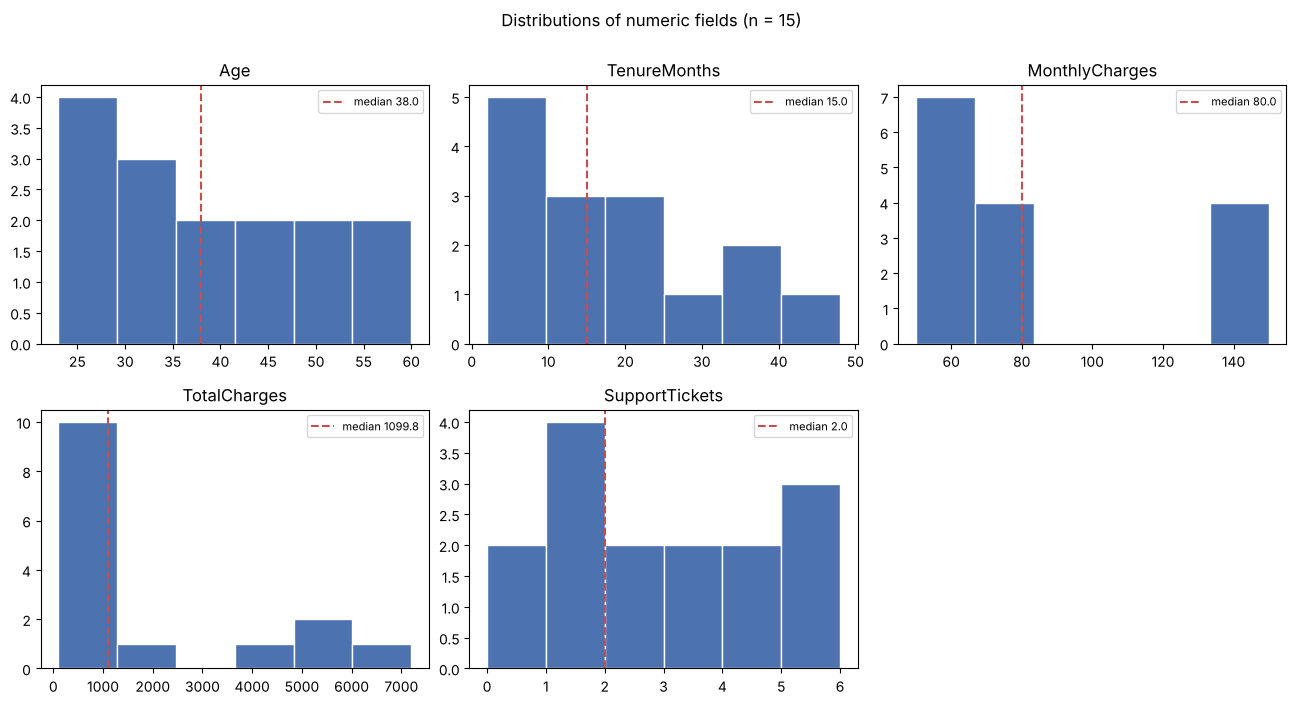

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(13, 7))
for ax, c in zip(axes.flat, ["Age", "TenureMonths", "MonthlyCharges", "TotalCharges", "SupportTickets"]):
    ax.hist(df[c], bins=6, color="#4C72B0", edgecolor="white")
    ax.axvline(df[c].median(), color="#C44E52", ls="--", label=f"median {df[c].median():.1f}")
    ax.set_title(c); ax.legend(fontsize=8)
axes.flat[-1].axis("off")
fig.suptitle("Distributions of numeric fields (n = 15)", y=1.0)
plt.tight_layout()
plt.savefig("charts/01_numeric_distributions.png", dpi=130)
plt.show()

### 3.1 Churn by segment

In [12]:
def churn_by(col):
    t = df.groupby(col, observed=True)["ChurnFlag"].agg(customers="count", churned="sum", churn_rate="mean")
    t["churn_rate"] = (t["churn_rate"] * 100).round(1)
    return t

for c in ["ContractType", "SubscriptionType", "PaymentMethod", "TenureBand", "Gender"]:
    print(f"--- Churn by {c} (churn_rate in %) ---")
    print(churn_by(c).to_string(), "\n")

--- Churn by ContractType (churn_rate in %) ---
                customers  churned  churn_rate
ContractType                                  
Month-to-Month          7        7       100.0
One Year                4        0         0.0
Two Year                4        0         0.0 

--- Churn by SubscriptionType (churn_rate in %) ---
                  customers  churned  churn_rate
SubscriptionType                                
Basic                     7        5        71.4
Enterprise                4        0         0.0
Pro                       4        2        50.0 

--- Churn by PaymentMethod (churn_rate in %) ---
               customers  churned  churn_rate
PaymentMethod                                
Bank Transfer          3        0         0.0
Credit Card            6        2        33.3
Debit Card             2        2       100.0
UPI                    4        3        75.0 

--- Churn by TenureBand (churn_rate in %) ---
            customers  churned  churn_rate


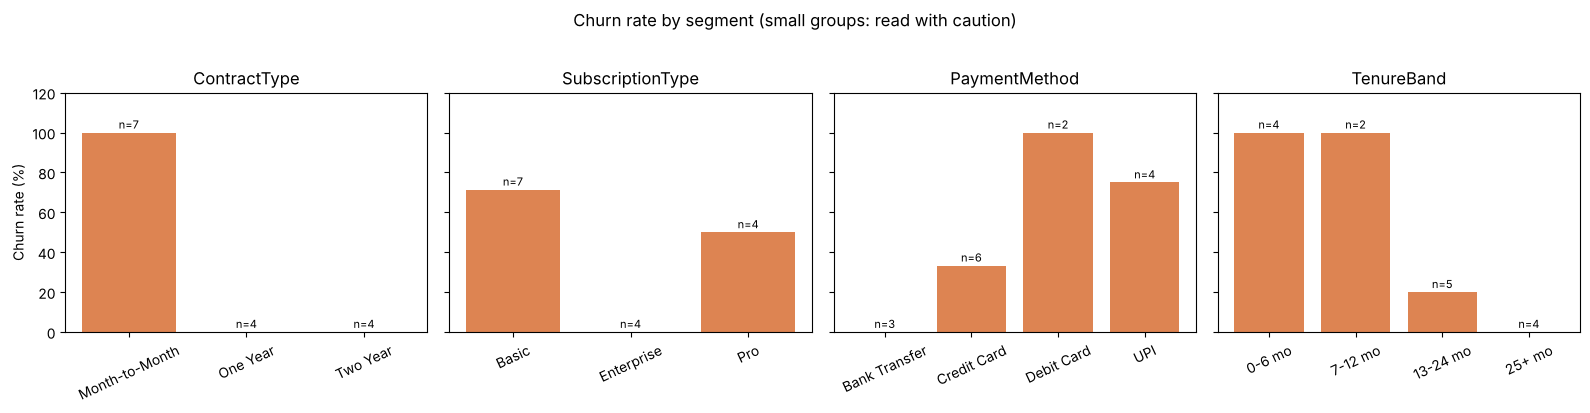

In [13]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4), sharey=True)
for ax, c in zip(axes, ["ContractType", "SubscriptionType", "PaymentMethod", "TenureBand"]):
    t = churn_by(c)
    bars = ax.bar(t.index.astype(str), t["churn_rate"], color="#DD8452")
    for b, n in zip(bars, t["customers"]):
        ax.text(b.get_x()+b.get_width()/2, b.get_height()+2, f"n={n}", ha="center", fontsize=8)
    ax.set_title(c); ax.set_ylim(0, 120); ax.tick_params(axis="x", rotation=25)
axes[0].set_ylabel("Churn rate (%)")
fig.suptitle("Churn rate by segment (small groups: read with caution)", y=1.02)
plt.tight_layout()
plt.savefig("charts/02_churn_by_segment.png", dpi=130, bbox_inches="tight")
plt.show()

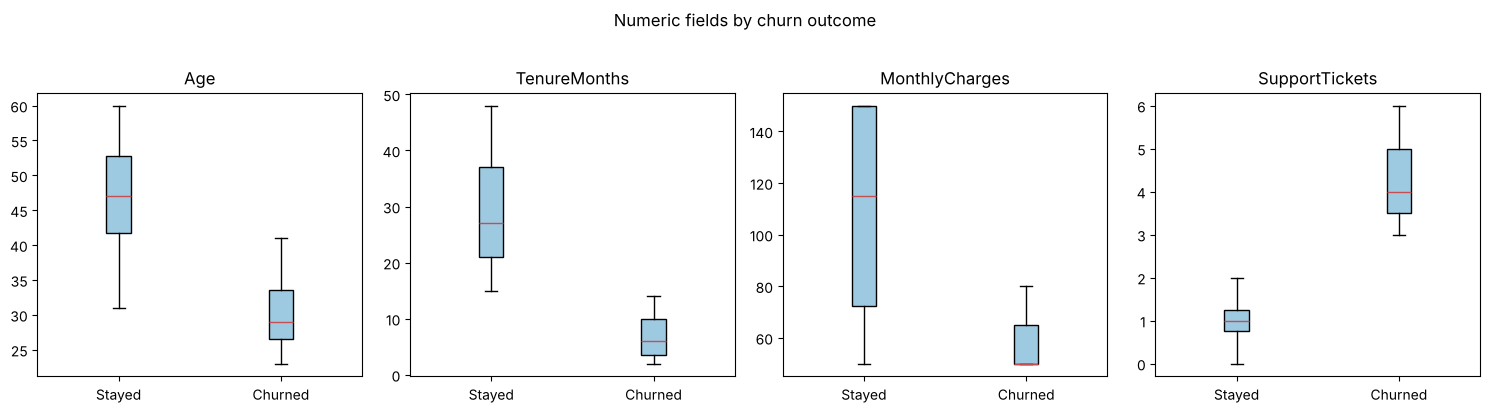

In [14]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, c in zip(axes, ["Age", "TenureMonths", "MonthlyCharges", "SupportTickets"]):
    data = [df.loc[df["Churn"] == g, c] for g in ["No", "Yes"]]
    ax.boxplot(data, tick_labels=["Stayed", "Churned"], patch_artist=True,
               boxprops=dict(facecolor="#9ecae1"), medianprops=dict(color="#C44E52"))
    ax.set_title(c)
fig.suptitle("Numeric fields by churn outcome", y=1.02)
plt.tight_layout()
plt.savefig("charts/03_numeric_by_churn.png", dpi=130, bbox_inches="tight")
plt.show()

In [15]:
profile = df.groupby("Churn", observed=True)[["Age", "TenureMonths", "MonthlyCharges", "SupportTickets"]].mean().round(1)
print("Average profile by outcome")
print(profile.to_string())
print()
print("Correlation with ChurnFlag (Pearson, n=15):")
print(df[["Age", "TenureMonths", "MonthlyCharges", "SupportTickets", "ChurnFlag"]].corr()["ChurnFlag"].drop("ChurnFlag").round(2).to_string())
print()
print("Contract x Subscription (customer counts) - shows overlap between the two drivers:")
print(pd.crosstab(df["ContractType"], df["SubscriptionType"]))

Average profile by outcome
        Age  TenureMonths  MonthlyCharges  SupportTickets
Churn                                                    
No     46.6          29.1           107.5             1.0
Yes    30.4           7.0            58.6             4.3

Correlation with ChurnFlag (Pearson, n=15):
Age              -0.73
TenureMonths     -0.80
MonthlyCharges   -0.59
SupportTickets    0.88

Contract x Subscription (customer counts) - shows overlap between the two drivers:
SubscriptionType  Basic  Enterprise  Pro
ContractType                            
Month-to-Month        5           0    2
One Year              2           0    2
Two Year              0           4    0


## 4. Initial findings

1. **Contract type separates churn most sharply.** All 7 Month-to-Month customers churned; none of the 8 One-Year or Two-Year customers did.
2. **Churners are newer and more support-heavy.** They average 7 months of tenure vs about 29 for stayers, and raise about 4.3 support tickets vs 1.0.
3. **Churners are younger and on cheaper plans.** Average age is about 30 vs 47, and average monthly charge is about $59 vs $107.
4. **Higher-priced tiers retain better, but this is confounded.** Enterprise customers never churned, yet every Enterprise customer is also on a Two-Year contract, so plan and contract effects cannot be separated here.
5. **Payment method looks related (Debit Card 100%, UPI 75%, Bank Transfer 0%), but groups hold only 2 to 4 customers**, so this is the weakest signal.

### Limitations and next steps
- **n = 15 is too small for inference.** The 100% / 0% splits are partly an artifact of tiny groups and a synthetic design.
- **Variables overlap.** Contract, plan, tenure, and price move together; `TotalCharges` is fully determined by tenure and price, so it adds no independent information.
- **Gender shows no meaningful pattern** (50% of women vs 43% of men churned, a one-customer difference at this size).
- **Next steps:** repeat this audit on a larger real extract, test contract effect while controlling for plan and tenure (e.g. logistic regression), and check whether early support tickets predict churn.